# UTS Pembelajaran Mesin - KNN - Naive Bayes
I Nyoman Arya Mas Sugiarthawan - 202431108 - Kelas H

Dataset: 03_counter_strike_2.csv


## Import Library

In [ ]:
# 202431108
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42

## Load Dataset

In [ ]:
# 202431108
data = pd.read_csv('03_counter_strike_2.csv')
print("Ukuran dataset:", data.shape)

Ukuran dataset: (2000, 14)


## Menampilkan Lima Baris Pertama

In [ ]:
# 202431108
display(data.head())

,time_left,ct_score,t_score,map,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets,round_winner
0,175.00,0.0,0.0,de_dust2,False,500.0,500.0,0.0,0.0,4000.0,4000.0,0.0,0.0,CT
1,156.03,0.0,0.0,de_dust2,False,500.0,500.0,400.0,300.0,600.0,650.0,0.0,0.0,CT
2,96.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,CT
3,76.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,CT
4,174.97,1.0,0.0,de_dust2,False,500.0,500.0,192.0,0.0,18350.0,10750.0,0.0,0.0,CT


## Informasi Struktur Dataset

In [ ]:
# 202431108
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   time_left     2000 non-null   float64
 1   ct_score      2000 non-null   float64
 2   t_score       2000 non-null   float64
 3   map           2000 non-null   object 
 4   bomb_planted  2000 non-null   bool   
 5   ct_health     2000 non-null   float64
 6   t_health      2000 non-null   float64
 7   ct_armor      2000 non-null   float64
 8   t_armor       2000 non-null   float64
 9   ct_money      2000 non-null   float64
 10  t_money       2000 non-null   float64
 11  ct_helmets    2000 non-null   float64
 12  t_helmets     2000 non-null   float64
 13  round_winner  2000 non-null   object 
dtypes: bool(1), float64(11), object(2)
memory usage: 205.2+ KB


## Statistik Deskriptif

In [ ]:
# 202431108
print(data.describe().T.round(2).to_string())

             count      mean       std   min      25%      50%       75%      max
time_left   2000.0     95.63     53.73  0.05    54.91    94.91    156.43    175.0
ct_score    2000.0      6.84      4.23  0.00     3.00     7.00     10.00     15.0
t_score     2000.0      6.29      4.19  0.00     3.00     6.00     10.00     15.0
ct_health   2000.0    406.17    137.62  2.00   315.75   500.00    500.00    500.0
t_health    2000.0    402.99    137.70  0.00   328.75   500.00    500.00    500.0
ct_armor    2000.0    306.75    172.86  0.00   188.00   300.00    488.00    500.0
t_armor     2000.0    309.54    168.69  0.00   190.00   362.00    467.00    500.0
ct_money    2000.0   7867.35   9017.49  0.00  1200.00  4000.00  11762.50  58050.0
t_money     2000.0  12377.60  12209.58  0.00  1700.00  9075.00  19250.00  67700.0
ct_helmets  2000.0      1.82      1.77  0.00     0.00     1.00      3.00      5.0
t_helmets   2000.0      3.01      1.96  0.00     1.00     4.00      5.00      5.0


## Pemeriksaan Missing Value dan Duplikasi

In [ ]:
# 202431108
print("Jumlah Missing Value:")
print(data.isnull().sum())

print("\nJumlah Data Duplikat:")
print(data.duplicated().sum())

Jumlah Missing Value:
time_left       0
ct_score        0
t_score         0
map             0
bomb_planted    0
ct_health       0
t_health        0
ct_armor        0
t_armor         0
ct_money        0
t_money         0
ct_helmets      0
t_helmets       0
round_winner    0
dtype: int64

Jumlah Data Duplikat:
39


## Identifikasi Fitur Numerik dan Kategorikal

In [ ]:
# 202431108
numerical_features = data.select_dtypes(include=np.number).columns.tolist()
categorical_features = data.select_dtypes(exclude=np.number).columns.tolist()

print("Jumlah fitur numerik:", len(numerical_features))
print("Daftar fitur numerik:", numerical_features)
print("\nJumlah fitur non-numerik:", len(categorical_features))
print("Daftar fitur non-numerik:", categorical_features)

Jumlah fitur numerik: 11
Daftar fitur numerik: ['time_left', 'ct_score', 't_score', 'ct_health', 't_health', 'ct_armor', 't_armor', 'ct_money', 't_money', 'ct_helmets', 't_helmets']

Jumlah fitur non-numerik: 3
Daftar fitur non-numerik: ['map', 'bomb_planted', 'round_winner']


## Melihat Nilai Unik Fitur Non-Numerik

In [ ]:
# 202431108
for col in categorical_features:
    print(f"\nKolom: {col}")
    print(data[col].unique())


Kolom: map
['de_dust2' 'de_mirage' 'de_nuke' 'de_inferno' 'de_overpass' 'de_vertigo'
 'de_train']

Kolom: bomb_planted
[False  True]

Kolom: round_winner
['CT' 'T']


## EDA Distribusi Target

round_winner
T     1176
CT     824
Name: count, dtype: int64
round_winner
T     58.8
CT    41.2
Name: proportion, dtype: float64


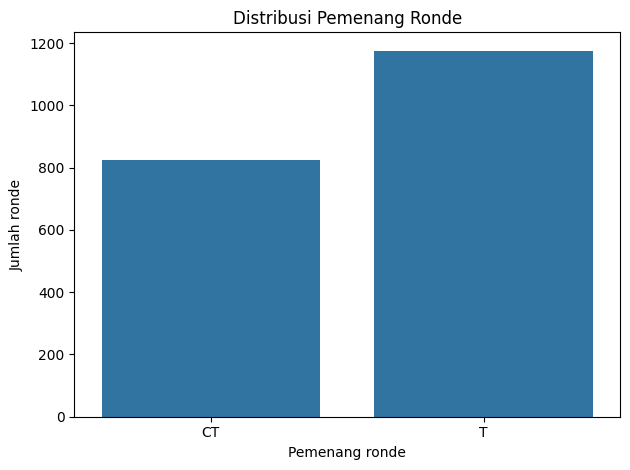

In [ ]:
# 202431108
print(data['round_winner'].value_counts())
print((data['round_winner'].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=data, x='round_winner')
plt.title('Distribusi Pemenang Ronde')
plt.xlabel('Pemenang ronde')
plt.ylabel('Jumlah ronde')
plt.tight_layout()
plt.show()

## EDA Distribusi Sisa Waktu Ronde

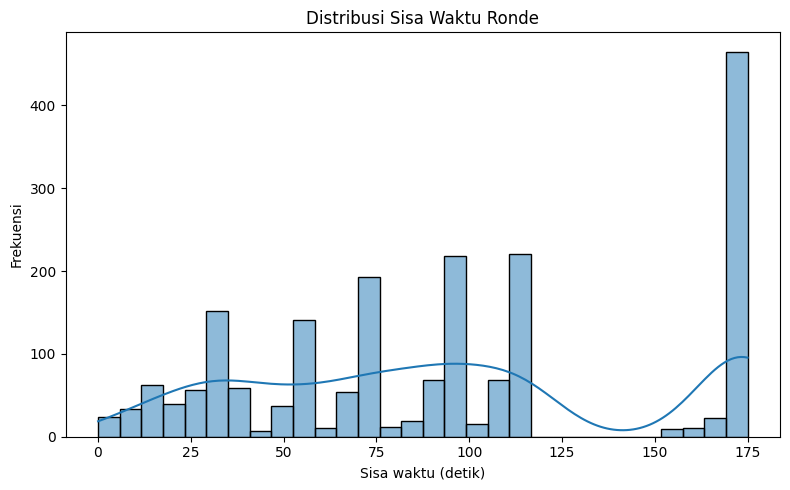

count    2000.00
mean       95.63
std        53.73
min         0.05
25%        54.91
50%        94.91
75%       156.43
max       175.00
Name: time_left, dtype: float64


In [ ]:
# 202431108
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x='time_left', bins=30, kde=True)
plt.title('Distribusi Sisa Waktu Ronde')
plt.xlabel('Sisa waktu (detik)')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()
print(data['time_left'].describe().round(2))

## EDA Pemenang Ronde pada Setiap Peta dan Status Bom

round_winner   CT    T
map                   
de_dust2      112  190
de_inferno     60  123
de_mirage     234  319
de_nuke       209  300
de_overpass    64  108
de_train       78   48
de_vertigo     67   88

round_winner     CT      T
bomb_planted              
False         0.445  0.555
True          0.193  0.807


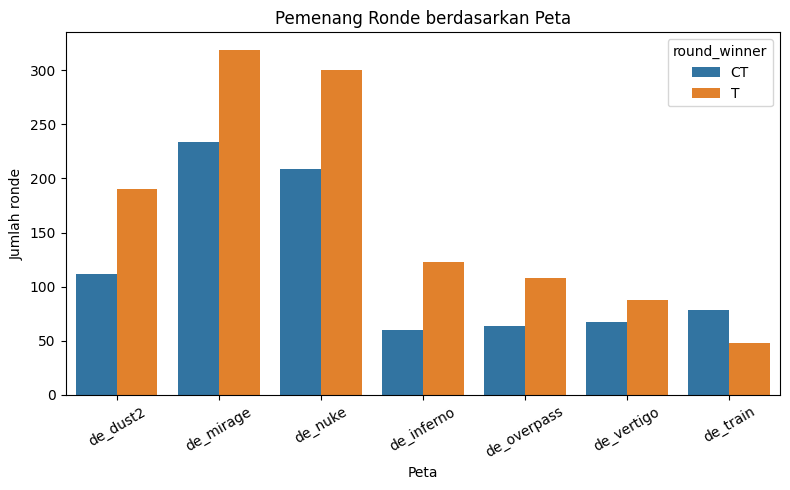

In [ ]:
# 202431108
print(pd.crosstab(data['map'], data['round_winner']))
print()
print(pd.crosstab(data['bomb_planted'], data['round_winner'],
                  normalize='index').round(3))

plt.figure(figsize=(8, 5))
sns.countplot(data=data, x='map', hue='round_winner')
plt.title('Pemenang Ronde berdasarkan Peta')
plt.xlabel('Peta')
plt.ylabel('Jumlah ronde')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## EDA Korelasi Antarfitur Numerik

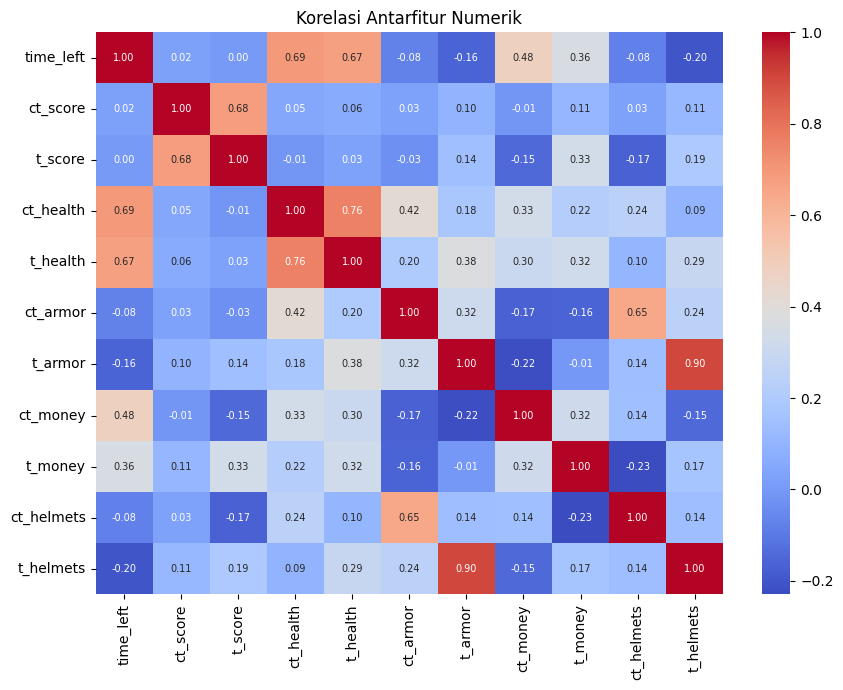

In [ ]:
# 202431108
plt.figure(figsize=(9, 7))
sns.heatmap(data[numerical_features].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', annot_kws={'size': 7})
plt.title('Korelasi Antarfitur Numerik')
plt.tight_layout()
plt.show()

## Menentukan Fitur dan Target

In [ ]:
# 202431108
X = data.drop(columns=['round_winner'])
X['bomb_planted'] = X['bomb_planted'].astype(int)
y = data['round_winner'].map({'T': 0, 'CT': 1})

print("Fitur prediktor:", X.columns.tolist())
print("\nDistribusi target:")
print(y.value_counts())

Fitur prediktor: ['time_left', 'ct_score', 't_score', 'map', 'bomb_planted', 'ct_health', 't_health', 'ct_armor', 't_armor', 'ct_money', 't_money', 'ct_helmets', 't_helmets']

Distribusi target:
round_winner
0    1176
1     824
Name: count, dtype: int64


## Membagi Data Training dan Testing

In [ ]:
# 202431108
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1600, 13)
X_test : (400, 13)
y_train: (1600,)
y_test : (400,)


## Preprocessing Data

In [ ]:
# 202431108
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = ['map']

preprocessor = ColumnTransformer(
    transformers=[
        ('numerik', StandardScaler(), numeric_cols),
        ('kategori', OneHotEncoder(handle_unknown='ignore',
                                   sparse_output=False), category_cols)
    ]
)

print("Kolom numerik :", numeric_cols)
print("Kolom kategori:", category_cols)
print("Preprocessing siap digunakan.")

Kolom numerik : ['time_left', 'ct_score', 't_score', 'bomb_planted', 'ct_health', 't_health', 'ct_armor', 't_armor', 'ct_money', 't_money', 'ct_helmets', 't_helmets']
Kolom kategori: ['map']
Preprocessing siap digunakan.


## Training Model Gaussian Naive Bayes

In [ ]:
# 202431108
model_gnb = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', GaussianNB())
])

model_gnb.fit(X_train, y_train)
print("Model Gaussian Naive Bayes berhasil dilatih.")

Model Gaussian Naive Bayes berhasil dilatih.


## Prediksi Data Testing

In [ ]:
# 202431108
y_pred = model_gnb.predict(X_test)
print("Lima belas hasil prediksi pertama:", y_pred[:15])

Lima belas hasil prediksi pertama: [0 1 1 0 1 0 1 0 0 0 1 1 0 0 1]


## Evaluasi Model

In [ ]:
# 202431108
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1-Score :", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1], target_names=['T', 'CT'],
    zero_division=0
))

Accuracy : 0.72
Precision: 0.653179190751445
Recall   : 0.6848484848484848
F1-Score : 0.6686390532544378

Classification Report:
              precision    recall  f1-score   support

           T       0.77      0.74      0.76       235
          CT       0.65      0.68      0.67       165

    accuracy                           0.72       400
   macro avg       0.71      0.71      0.71       400
weighted avg       0.72      0.72      0.72       400



## Confusion Matrix

Confusion Matrix Gaussian Naive Bayes:
[[175  60]
 [ 52 113]]
TN=175, FP=60, FN=52, TP=113


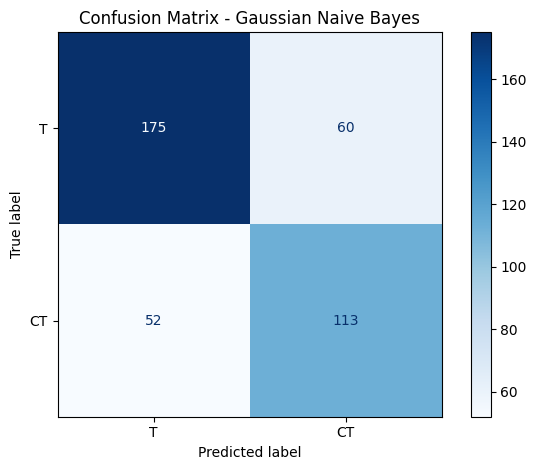

In [ ]:
# 202431108
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion Matrix Gaussian Naive Bayes:")
print(cm)

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['T', 'CT']
).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Gaussian Naive Bayes')
plt.tight_layout()
plt.show()

## Parameter Hasil Pelatihan Gaussian Naive Bayes

In [ ]:
# 202431108
gnb = model_gnb.named_steps['classifier']
feature_names = model_gnb.named_steps['preprocessing'].get_feature_names_out()

print("Jumlah fitur setelah preprocessing:", len(feature_names))
print("Prior kelas [T, CT]:", gnb.class_prior_.round(4))
print("Jumlah data latih per kelas:", gnb.class_count_)

params = pd.DataFrame(gnb.theta_, index=['T', 'CT'], columns=feature_names)
print("\nRata-rata (theta) beberapa fitur per kelas:")
params.columns = [c.split('__')[1] for c in params.columns]
print(params[['ct_health', 't_health', 'ct_armor', 'bomb_planted']].round(3).to_string())
print("\nAccuracy data training:", accuracy_score(y_train, model_gnb.predict(X_train)))

Jumlah fitur setelah preprocessing: 19
Prior kelas [T, CT]: [0.5881 0.4119]
Jumlah data latih per kelas: [941. 659.]

Rata-rata (theta) beberapa fitur per kelas:
    ct_health  t_health  ct_armor  bomb_planted
T      -0.153     0.077    -0.243         0.150
CT      0.218    -0.111     0.347        -0.214

Accuracy data training: 0.720625


## Pengujian Nilai var_smoothing

var_smoothing  accuracy  f1_ct
        1e-09    0.7200 0.6686
        1e-06    0.7200 0.6686
        1e-03    0.7225 0.6726
        1e-01    0.7275 0.6804
        1e+00    0.7400 0.6688


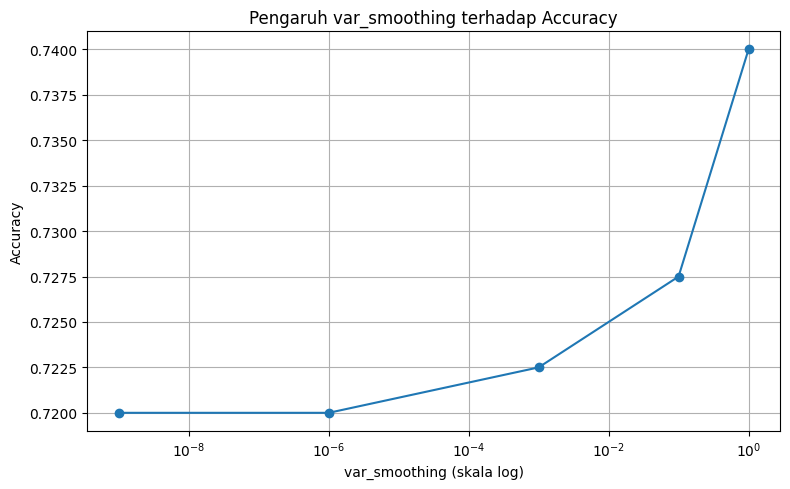

In [ ]:
# 202431108
smoothing_values = [1e-9, 1e-6, 1e-3, 1e-1, 1]
hasil = []

for vs in smoothing_values:
    model_temp = Pipeline(steps=[
        ('preprocessing', preprocessor),
        ('classifier', GaussianNB(var_smoothing=vs))
    ])
    model_temp.fit(X_train, y_train)
    pred_temp = model_temp.predict(X_test)
    hasil.append([f'{vs:.0e}', accuracy_score(y_test, pred_temp),
                  f1_score(y_test, pred_temp)])

hasil_df = pd.DataFrame(hasil, columns=['var_smoothing', 'accuracy', 'f1_ct'])
print(hasil_df.round(4).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.semilogx(smoothing_values, hasil_df['accuracy'], marker='o')
plt.title('Pengaruh var_smoothing terhadap Accuracy')
plt.xlabel('var_smoothing (skala log)')
plt.ylabel('Accuracy')
plt.grid(True)
plt.tight_layout()
plt.show()

## Preprocessing untuk KNN

In [ ]:
# 202431108
# Fitur dan pembagian data sama dengan Gaussian Naive Bayes agar perbandingan adil
preprocessor_knn = ColumnTransformer(
    transformers=[
        ('numerik', StandardScaler(), numeric_cols),
        ('kategori', OneHotEncoder(handle_unknown='ignore',
                                   sparse_output=False), category_cols)
    ]
)

print("X_train KNN:", X_train.shape)
print("X_test KNN :", X_test.shape)
print("Preprocessing KNN siap digunakan.")

X_train KNN: (1600, 13)
X_test KNN : (400, 13)
Preprocessing KNN siap digunakan.


## Training Model KNN dengan k=5

In [ ]:
# 202431108
model_knn = Pipeline(steps=[
    ('preprocessing', preprocessor_knn),
    ('classifier', KNeighborsClassifier(n_neighbors=5, weights='uniform'))
])

model_knn.fit(X_train, y_train)
print("Model KNN dengan k=5 berhasil dilatih.")

Model KNN dengan k=5 berhasil dilatih.


## Prediksi Data Testing KNN

In [ ]:
# 202431108
y_pred_knn = model_knn.predict(X_test)
print("Lima belas hasil prediksi pertama:", y_pred_knn[:15])

Lima belas hasil prediksi pertama: [1 1 0 0 1 0 1 0 0 1 0 0 0 1 1]


## Evaluasi Model KNN

In [ ]:
# 202431108
print("Accuracy :", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_knn, zero_division=0))
print("F1-Score :", f1_score(y_test, y_pred_knn, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_knn,
    labels=[0, 1], target_names=['T', 'CT'],
    zero_division=0
))

Accuracy : 0.86
Precision: 0.8609271523178808
Recall   : 0.7878787878787878
F1-Score : 0.8227848101265823

Classification Report:
              precision    recall  f1-score   support

           T       0.86      0.91      0.88       235
          CT       0.86      0.79      0.82       165

    accuracy                           0.86       400
   macro avg       0.86      0.85      0.85       400
weighted avg       0.86      0.86      0.86       400



## Confusion Matrix KNN

Confusion Matrix KNN:
[[214  21]
 [ 35 130]]
TN=214, FP=21, FN=35, TP=130


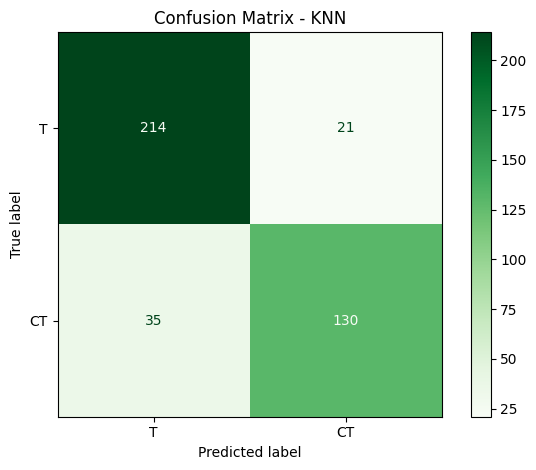

In [ ]:
# 202431108
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=[0, 1])
print("Confusion Matrix KNN:")
print(cm_knn)

tn, fp, fn, tp = cm_knn.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=['T', 'CT']
).plot(cmap='Greens', values_format='d')
plt.title('Confusion Matrix - KNN')
plt.tight_layout()
plt.show()

## Menguji Beberapa Nilai k pada KNN

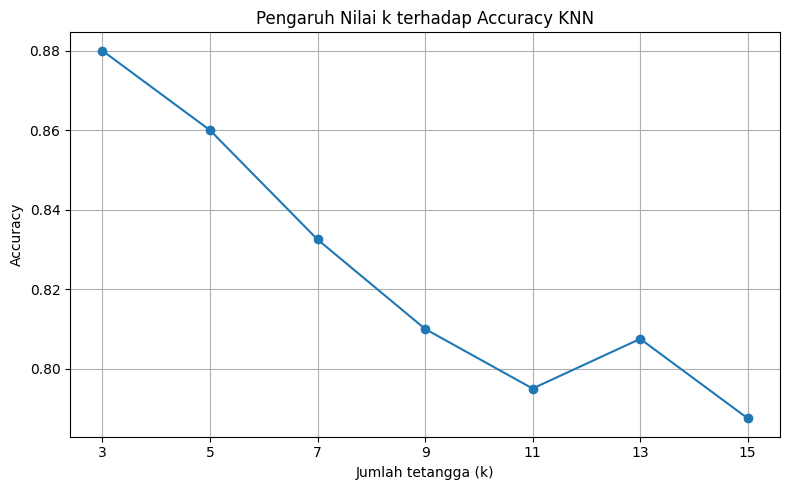

Accuracy setiap k: {3: 0.88, 5: 0.86, 7: 0.8325, 9: 0.81, 11: 0.795, 13: 0.8075, 15: 0.7875}


In [ ]:
# 202431108
# Data ditransformasikan satu kali; scaler/encoder hanya di-fit pada training
X_train_t = preprocessor_knn.fit_transform(X_train)
X_test_t = preprocessor_knn.transform(X_test)

k_values = range(3, 16, 2)
accuracies = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_t, y_train)
    pred_temp = knn_temp.predict(X_test_t)
    accuracies.append(accuracy_score(y_test, pred_temp))

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), accuracies, marker='o')
plt.title('Pengaruh Nilai k terhadap Accuracy KNN')
plt.xlabel('Jumlah tetangga (k)')
plt.ylabel('Accuracy')
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

print("Accuracy setiap k:", {k: round(float(a), 4) for k, a in zip(k_values, accuracies)})

## Evaluasi KNN dengan Nilai k Terbaik

In [ ]:
# 202431108
best_k = list(k_values)[int(np.argmax(accuracies))]
print("Nilai k dengan accuracy tertinggi pada percobaan:", best_k)

best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_t, y_train)
best_pred = best_knn.predict(X_test_t)

print(classification_report(
    y_test, best_pred,
    labels=[0, 1], target_names=['T', 'CT'],
    zero_division=0
))

Nilai k dengan accuracy tertinggi pada percobaan: 3
              precision    recall  f1-score   support

           T       0.89      0.91      0.90       235
          CT       0.87      0.84      0.85       165

    accuracy                           0.88       400
   macro avg       0.88      0.87      0.88       400
weighted avg       0.88      0.88      0.88       400



## Perbandingan Gaussian Naive Bayes dan KNN

               Model  Accuracy  Precision_CT  Recall_CT  F1_CT
Gaussian Naive Bayes      0.72        0.6532     0.6848 0.6686
           KNN (k=5)      0.86        0.8609     0.7879 0.8228
           KNN (k=3)      0.88        0.8679     0.8364 0.8519


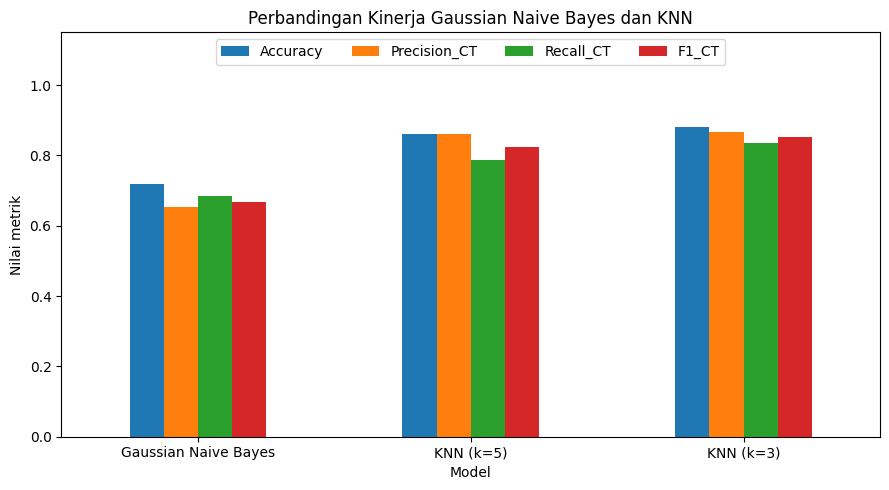

In [ ]:
# 202431108
perbandingan = pd.DataFrame({
    'Model': ['Gaussian Naive Bayes', 'KNN (k=5)', f'KNN (k={best_k})'],
    'Accuracy': [accuracy_score(y_test, y_pred),
                 accuracy_score(y_test, y_pred_knn),
                 accuracy_score(y_test, best_pred)],
    'Precision_CT': [precision_score(y_test, y_pred),
                     precision_score(y_test, y_pred_knn),
                     precision_score(y_test, best_pred)],
    'Recall_CT': [recall_score(y_test, y_pred),
                  recall_score(y_test, y_pred_knn),
                  recall_score(y_test, best_pred)],
    'F1_CT': [f1_score(y_test, y_pred),
              f1_score(y_test, y_pred_knn),
              f1_score(y_test, best_pred)]
})
print(perbandingan.round(4).to_string(index=False))

perbandingan.set_index('Model').plot(kind='bar', figsize=(9, 5))
plt.title('Perbandingan Kinerja Gaussian Naive Bayes dan KNN')
plt.ylabel('Nilai metrik')
plt.ylim(0, 1.15)
plt.xticks(rotation=0)
plt.legend(loc='upper center', ncol=4)
plt.tight_layout()
plt.show()